**The objective of this project is to develop a machine learning-based credit default risk prediction system using applicant data from the Home Credit dataset. The dataset contains information such as annual income, loan amount, annuity, employment status, education, housing characteristics, and external credit risk scores. The system will analyze these variables to predict whether a loan applicant is likely to experience payment difficulties.**

---






<mark>1. ***<u>Classification: Develop a machine learning model that can accurately predict Credit default.</u>***</mark>






---




#<mark> **1. Import Libraries**</mark>



**We're grouping imports by purpose: data handling, visualization, preprocessing, models, evaluation, and saving. Keeping imports grouped like this makes it easy to see at a glance what the notebook is going to do**



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, f1_score, recall_score


#<mark> 2. Load the Dataset</mark>

**We load the CSV and take a first look at its shape and the first few rows. This is always the very first step - you can't make any decisions about a dataset until you've actually looked at it.**

In [2]:
df = pd.read_csv("application_data.csv")

In [3]:
#Looking for the number of ROW'S and COLUMN'S that i have.
df.shape

(307511, 122)

In [4]:
#Looking for first five rows
df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [5]:
#Looking at last five rows
df.tail()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
307506,456251,0,Cash loans,M,N,N,0,157500.0,254700.0,27558.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
307507,456252,0,Cash loans,F,N,Y,0,72000.0,269550.0,12001.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
307508,456253,0,Cash loans,F,N,Y,0,153000.0,677664.0,29979.0,...,0,0,0,0,1.0,0.0,0.0,1.0,0.0,1.0
307509,456254,1,Cash loans,F,N,Y,0,171000.0,370107.0,20205.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
307510,456255,0,Cash loans,F,N,N,0,157500.0,675000.0,49117.5,...,0,0,0,0,0.0,0.0,0.0,2.0,0.0,1.0


##<mark> **3. EDA (Exploratory Data Analysis)**</mark>

 **EDA is the process of understanding, exploring, and summarizing a dataset before building a machine learning model. Its goal is to discover patterns, identify problems, and prepare the data for modelling.**

In [6]:
#A quick summery of dataset
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), object(16)
memory usage: 286.2+ MB
None


In [7]:
print(df.describe(include='all'))

           SK_ID_CURR         TARGET NAME_CONTRACT_TYPE CODE_GENDER  \
count   307511.000000  307511.000000             307511      307511   
unique            NaN            NaN                  2           3   
top               NaN            NaN         Cash loans           F   
freq              NaN            NaN             278232      202448   
mean    278180.518577       0.080729                NaN         NaN   
std     102790.175348       0.272419                NaN         NaN   
min     100002.000000       0.000000                NaN         NaN   
25%     189145.500000       0.000000                NaN         NaN   
50%     278202.000000       0.000000                NaN         NaN   
75%     367142.500000       0.000000                NaN         NaN   
max     456255.000000       1.000000                NaN         NaN   

       FLAG_OWN_CAR FLAG_OWN_REALTY   CNT_CHILDREN  AMT_INCOME_TOTAL  \
count        307511          307511  307511.000000      3.075110e+05   
uni

In [8]:
#Looking for null values
print(df.isnull().sum())

SK_ID_CURR                        0
TARGET                            0
NAME_CONTRACT_TYPE                0
CODE_GENDER                       0
FLAG_OWN_CAR                      0
                              ...  
AMT_REQ_CREDIT_BUREAU_DAY     41519
AMT_REQ_CREDIT_BUREAU_WEEK    41519
AMT_REQ_CREDIT_BUREAU_MON     41519
AMT_REQ_CREDIT_BUREAU_QRT     41519
AMT_REQ_CREDIT_BUREAU_YEAR    41519
Length: 122, dtype: int64


In [9]:
#To inspect missing values

missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean() * 100
})

print(missing[missing["Missing_Count"] > 0].sort_values(
    "Missing_Percentage", ascending=False
))

                          Missing_Count  Missing_Percentage
COMMONAREA_MEDI                  214865           69.872297
COMMONAREA_MODE                  214865           69.872297
COMMONAREA_AVG                   214865           69.872297
NONLIVINGAPARTMENTS_MODE         213514           69.432963
NONLIVINGAPARTMENTS_MEDI         213514           69.432963
...                                 ...                 ...
EXT_SOURCE_2                        660            0.214626
AMT_GOODS_PRICE                     278            0.090403
AMT_ANNUITY                          12            0.003902
CNT_FAM_MEMBERS                       2            0.000650
DAYS_LAST_PHONE_CHANGE                1            0.000325

[67 rows x 2 columns]


In [10]:
import pandas as pd

# Configure pandas to display all rows
with pd.option_context('display.max_rows', None):
    display(missing[missing["Missing_Count"] > 0].sort_values("Missing_Percentage", ascending=False))

,Missing_Count,Missing_Percentage
COMMONAREA_MEDI,214865,69.872297
COMMONAREA_MODE,214865,69.872297
COMMONAREA_AVG,214865,69.872297
NONLIVINGAPARTMENTS_MODE,213514,69.432963
NONLIVINGAPARTMENTS_MEDI,213514,69.432963
NONLIVINGAPARTMENTS_AVG,213514,69.432963
FONDKAPREMONT_MODE,210295,68.386172
LIVINGAPARTMENTS_AVG,210199,68.354953
LIVINGAPARTMENTS_MEDI,210199,68.354953
LIVINGAPARTMENTS_MODE,210199,68.354953


In [11]:
#Looking duplicate values
print(df.duplicated().sum())

0


In [12]:
null_counts = df.isnull().sum()

columns_with_less_than_500_null = null_counts[null_counts < 500].index

columns_with_more_than_500_null = null_counts[null_counts > 500].index

print("Columns with less than 500 null values:")
print(columns_with_less_than_500_null)

print("\nColumns with more than 500 null values:")
print(columns_with_more_than_500_null)

Columns with less than 500 null values:
Index(['SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER',
       'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL',
       'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'NAME_INCOME_TYPE',
       'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE',
       'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED',
       'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'FLAG_MOBIL', 'FLAG_EMP_PHONE',
       'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL',
       'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT',
       'REGION_RATING_CLIENT_W_CITY', 'WEEKDAY_APPR_PROCESS_START',
       'HOUR_APPR_PROCESS_START', 'REG_REGION_NOT_LIVE_REGION',
       'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION',
       'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY',
       'LIVE_CITY_NOT_WORK_CITY', 'ORGANIZATION_TYPE',
       'DAYS_LAST_PHONE_CHANGE', 'FLAG_DOCUMENT_2', 'FLAG_DOCUMENT_3',
       'FL

In [13]:
df = df.drop(columns_with_more_than_500_null, axis=1)

In [14]:
df.shape

(307511, 59)

In [15]:
df.isnull().sum().sort_values(ascending=False)

,0
AMT_GOODS_PRICE,278
AMT_ANNUITY,12
CNT_FAM_MEMBERS,2
DAYS_LAST_PHONE_CHANGE,1
NAME_CONTRACT_TYPE,0
CODE_GENDER,0
TARGET,0
CNT_CHILDREN,0
FLAG_OWN_REALTY,0
AMT_CREDIT,0


### **3.1 Visualizing Target Distribution and Key Features**
Let's plot the distribution of our target variable `TARGET` (unbalance check) and analyze key correlations and distributions using `seaborn` and `matplotlib`.

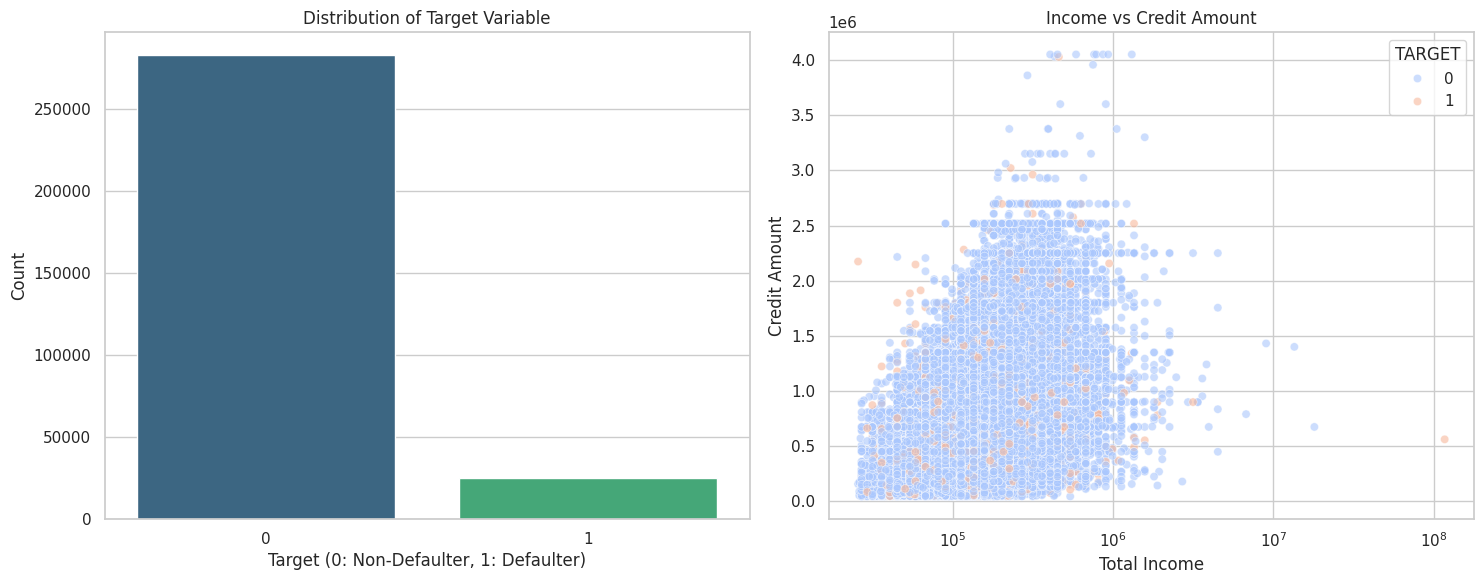

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style='whitegrid')

# Create a figure with subplots
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Target Class Distribution
sns.countplot(x='TARGET', data=df, ax=axes[0], palette='viridis')
axes[0].set_title('Distribution of Target Variable')
axes[0].set_xlabel('Target (0: Non-Defaulter, 1: Defaulter)')
axes[0].set_ylabel('Count')

# 2. Income vs Credit Amount colored by Target
sns.scatterplot(x='AMT_INCOME_TOTAL', y='AMT_CREDIT', hue='TARGET', data=df, alpha=0.6, ax=axes[1], palette='coolwarm')
axes[1].set_title('Income vs Credit Amount')
axes[1].set_xlabel('Total Income')
axes[1].set_ylabel('Credit Amount')
axes[1].set_xscale('log')  # Using log scale due to potential extreme values in income

plt.tight_layout()
plt.show()

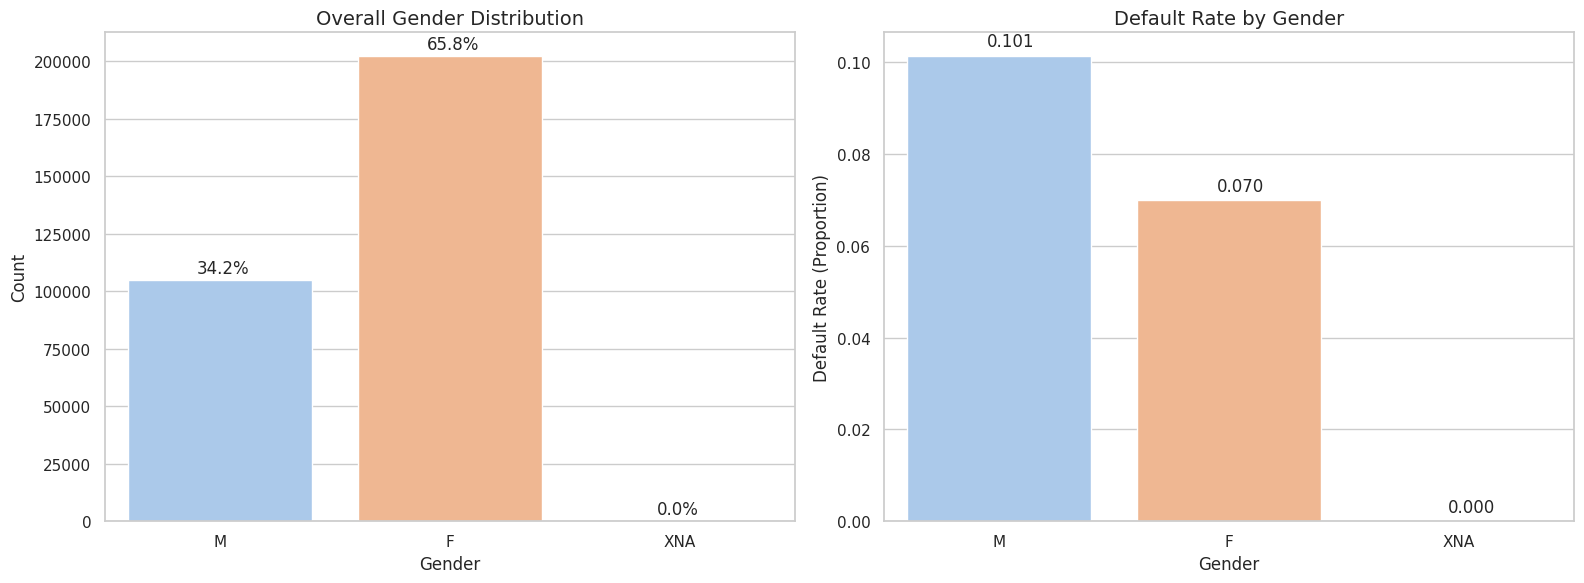

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Ensure df is defined
if 'df' not in locals() and 'df' not in globals():
    df = pd.read_csv('application_data.csv')

# Set the style
sns.set_theme(style='whitegrid')

# Create a figure with subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Gender Distribution (Overall Counts)
sns.countplot(x='CODE_GENDER', data=df, ax=axes[0], palette='pastel')
axes[0].set_title('Overall Gender Distribution', fontsize=14)
axes[0].set_xlabel('Gender')
axes[0].set_ylabel('Count')

# Add percentages on top of bars
total_applicants = len(df['CODE_GENDER'].dropna())
for p in axes[0].patches:
    percentage = f'{100 * p.get_height() / total_applicants:.1f}%'
    x = p.get_x() + p.get_width() / 2 - 0.1
    y = p.get_height() + (total_applicants * 0.01)
    axes[0].annotate(percentage, (x, y), fontsize=12)

# 2. Gender vs Target (Default Rates)
sns.barplot(x='CODE_GENDER', y='TARGET', data=df, ax=axes[1], palette='pastel', ci=None)
axes[1].set_title('Default Rate by Gender', fontsize=14)
axes[1].set_xlabel('Gender')
axes[1].set_ylabel('Default Rate (Proportion)')

# Add exact rates on top of bars
for p in axes[1].patches:
    rate = f'{p.get_height():.3f}'
    x = p.get_x() + p.get_width() / 2 - 0.05
    y = p.get_height() + 0.002
    axes[1].annotate(rate, (x, y), fontsize=12)

plt.tight_layout()
plt.show()

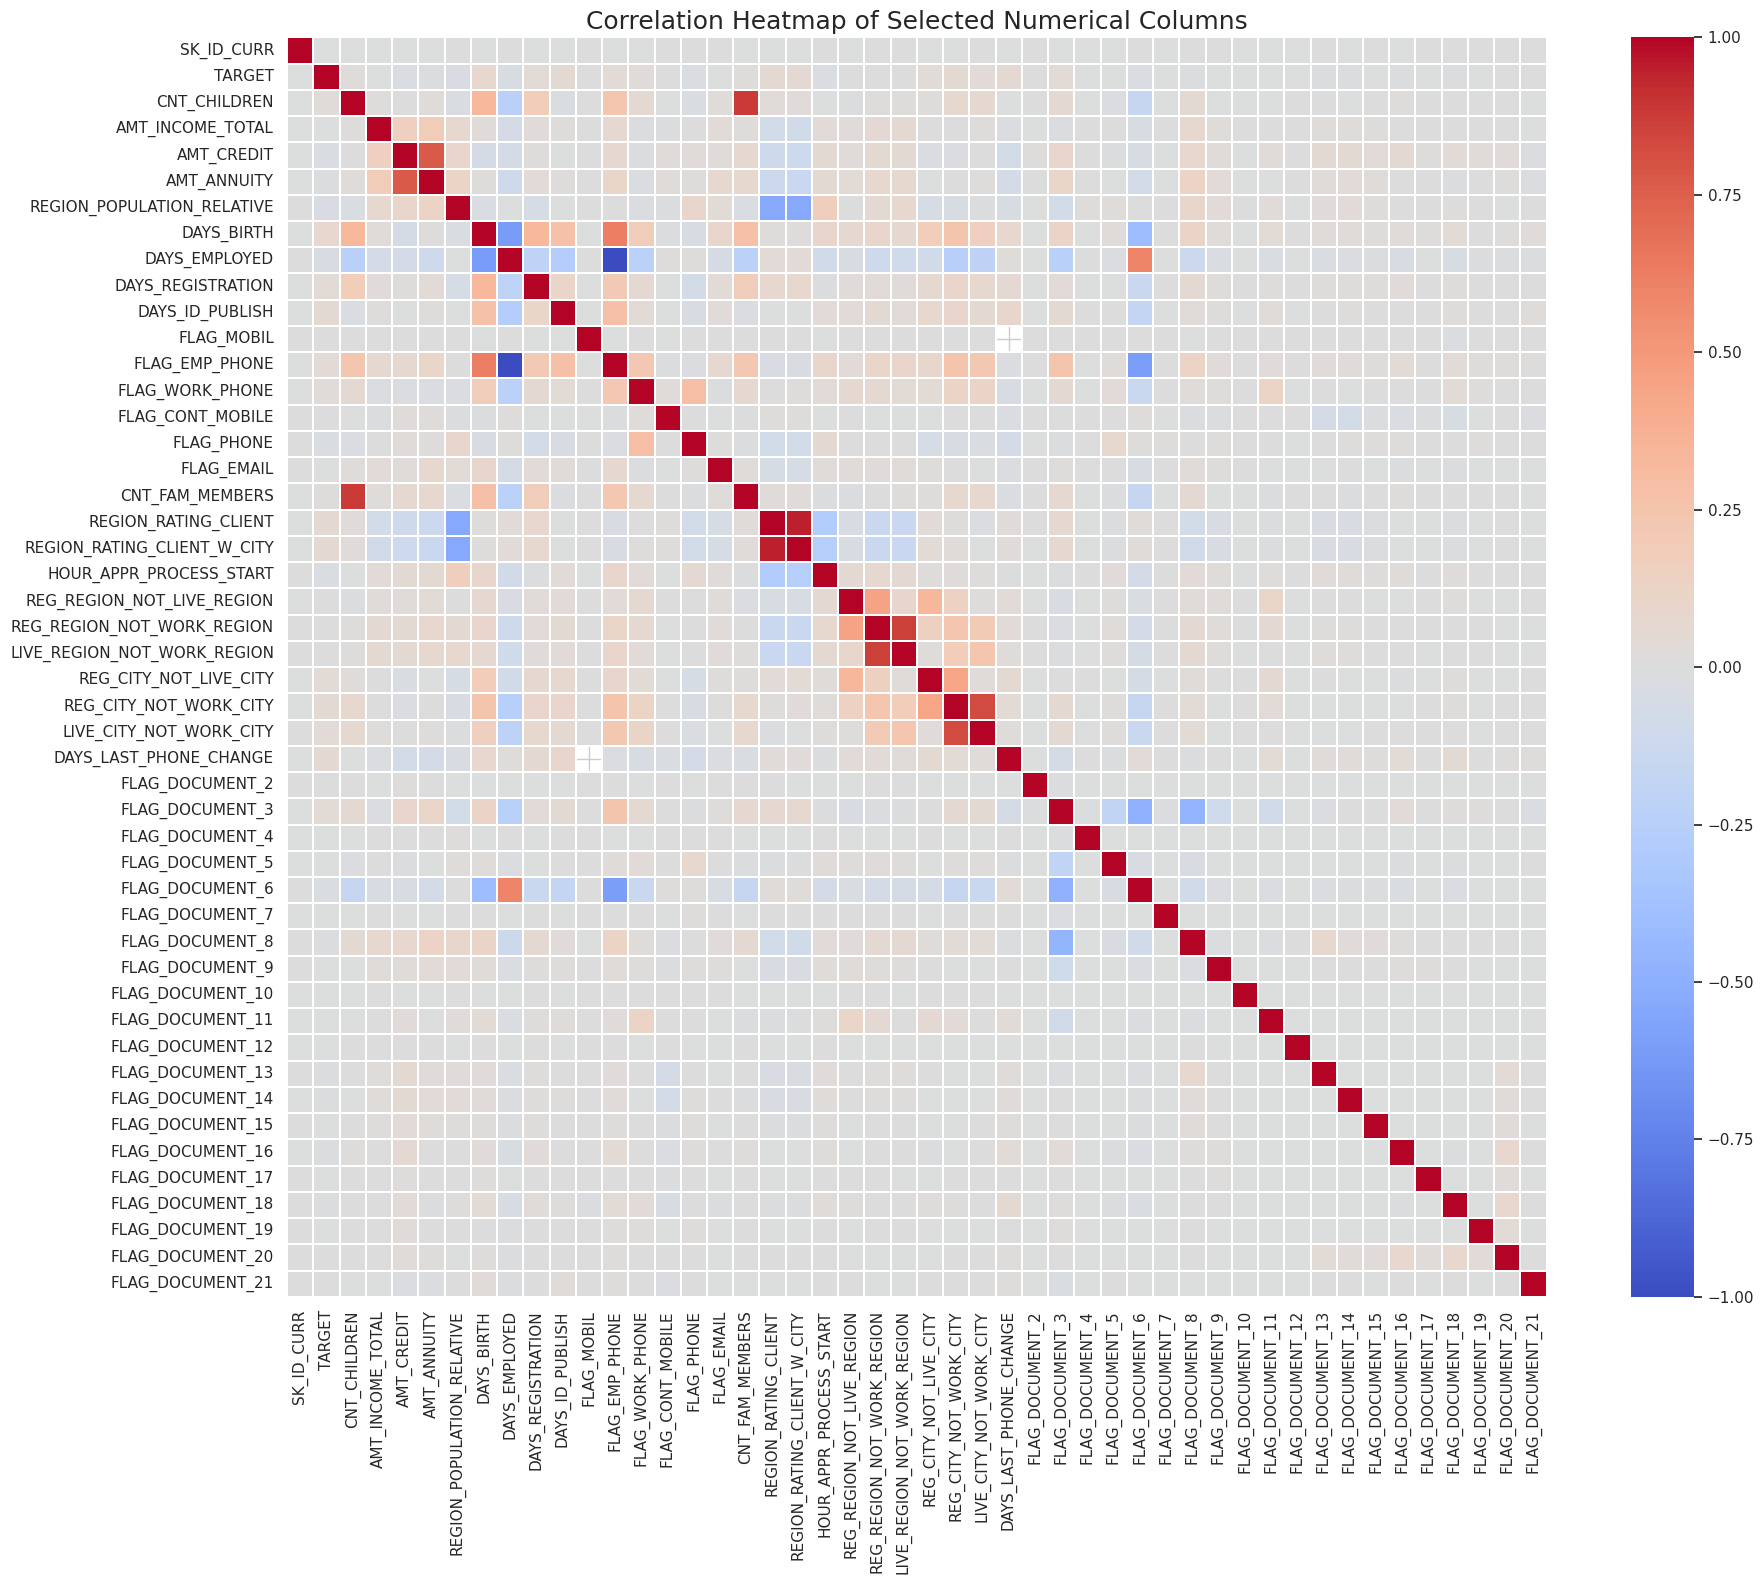

In [18]:


# List of requested columns
requested_cols = [
    'SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER',
    'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL',
    'AMT_CREDIT', 'AMT_ANNUITY', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE',
    'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'REGION_POPULATION_RELATIVE',
    'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH',
    'FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE',
    'FLAG_PHONE', 'FLAG_EMAIL', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT',
    'REGION_RATING_CLIENT_W_CITY', 'WEEKDAY_APPR_PROCESS_START',
    'HOUR_APPR_PROCESS_START', 'REG_REGION_NOT_LIVE_REGION',
    'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION',
    'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY',
    'LIVE_CITY_NOT_WORK_CITY', 'ORGANIZATION_TYPE',
    'DAYS_LAST_PHONE_CHANGE', 'FLAG_DOCUMENT_2', 'FLAG_DOCUMENT_3',
    'FLAG_DOCUMENT_4', 'FLAG_DOCUMENT_5', 'FLAG_DOCUMENT_6',
    'FLAG_DOCUMENT_7', 'FLAG_DOCUMENT_8', 'FLAG_DOCUMENT_9',
    'FLAG_DOCUMENT_10', 'FLAG_DOCUMENT_11', 'FLAG_DOCUMENT_12',
    'FLAG_DOCUMENT_13', 'FLAG_DOCUMENT_14', 'FLAG_DOCUMENT_15',
    'FLAG_DOCUMENT_16', 'FLAG_DOCUMENT_17', 'FLAG_DOCUMENT_18',
    'FLAG_DOCUMENT_19', 'FLAG_DOCUMENT_20', 'FLAG_DOCUMENT_21'
]

# Filter columns that are in the dataframe
existing_cols = [col for col in requested_cols if col in df.columns]

# Select only numerical columns for correlation calculation
numeric_cols = df[existing_cols].select_dtypes(include=[np.number]).columns.tolist()

# Calculate correlation matrix
corr_matrix = df[numeric_cols].corr()

# Plot heatmap
plt.figure(figsize=(20, 16))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1, center=0, square=True, linewidths=0.1)
plt.title('Correlation Heatmap of Selected Numerical Columns', fontsize=18)
plt.tight_layout()
plt.show()

### **4. Preprocessing & Feature Importance**
To extract feature importance, we will:
1. Fill the remaining small amount of missing values (like `AMT_ANNUITY` and `CNT_FAM_MEMBERS`).
2. Encode the categorical variables using Label Encoding.
3. Fit a fast baseline Random Forest classifier.
4. Extract and plot the top 20 most important features.

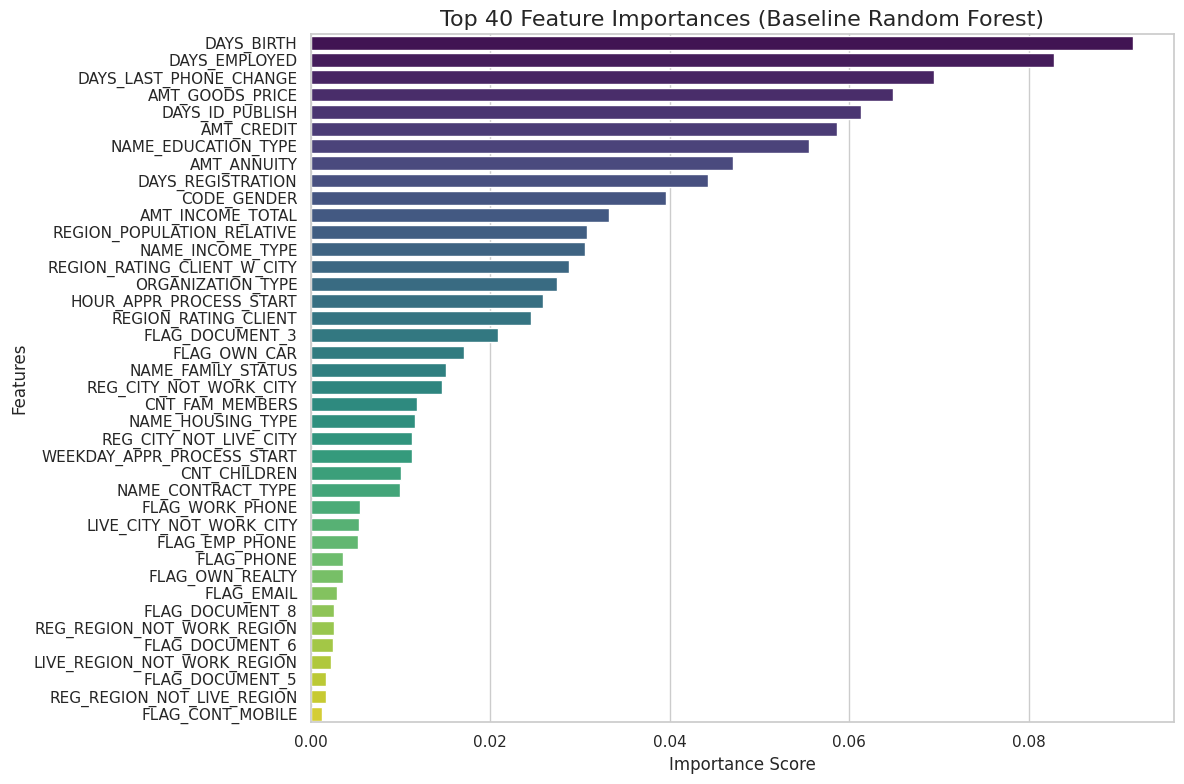

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder

# Make a copy of the dataframe to avoid altering original EDA data
prep_df = df.copy()

# Drop ID column as it is not a feature
if 'SK_ID_CURR' in prep_df.columns:
    prep_df = prep_df.drop(columns=['SK_ID_CURR'])

# Separate target
y = prep_df['TARGET']
X = prep_df.drop(columns=['TARGET'])

# Impute missing values with median for numeric, and mode for categorical
for col in X.columns:
    if X[col].dtype == 'object':
        X[col] = X[col].fillna(X[col].mode()[0])
        # Encode categorical variable
        le = LabelEncoder()
        X[col] = le.fit_transform(X[col].astype(str))
    else:
        X[col] = X[col].fillna(X[col].median())

# Fit a quick Random Forest model to determine feature importances
rf = RandomForestClassifier(n_estimators=50, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X, y)

# Get feature importances
importances = rf.feature_importances_
feature_names = X.columns
importances_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
importances_df = importances_df.sort_values(by='Importance', ascending=False).head(40)

# Plot top 20 feature importances
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=importances_df, palette='viridis')
plt.title('Top 40 Feature Importances (Baseline Random Forest)', fontsize=16)
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

### **5. Applying One-Hot Encoding & Label Encoding**
To process our categorical features properly for a wider variety of models:
* We apply **Label Encoding** to binary object columns (columns with 2 or fewer unique categories).
* We apply **One-Hot Encoding** (via `pd.get_dummies`) to columns with more than 2 unique categories.

In [20]:
from sklearn.preprocessing import LabelEncoder

# Working with a clean copy of the dataframe
encoded_df = df.copy()

# Identify categorical columns
cat_cols = encoded_df.select_dtypes(include=['object']).columns.tolist()

binary_cols = []
multiclass_cols = []

for col in cat_cols:
    # Fill missing values with the mode temporarily for encoding
    encoded_df[col] = encoded_df[col].fillna(encoded_df[col].mode()[0])
    num_unique = encoded_df[col].nunique()
    if num_unique <= 2:
        binary_cols.append(col)
    else:
        multiclass_cols.append(col)

print(f"Applying Label Encoding to binary columns: {binary_cols}")
print(f"Applying One-Hot Encoding to multiclass columns: {multiclass_cols}")

# 1. Apply Label Encoding
le = LabelEncoder()
for col in binary_cols:
    encoded_df[col] = le.fit_transform(encoded_df[col])

# 2. Apply One-Hot Encoding
encoded_df = pd.get_dummies(encoded_df, columns=multiclass_cols, drop_first=True, dtype = int)

# Confirm shape change and display first few rows
print(f"\nNew DataFrame shape after encoding: {encoded_df.shape}")
display(encoded_df.head())

Applying Label Encoding to binary columns: ['NAME_CONTRACT_TYPE', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY']
Applying One-Hot Encoding to multiclass columns: ['CODE_GENDER', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE']

New DataFrame shape after encoding: (307511, 138)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,ORGANIZATION_TYPE_Trade: type 4,ORGANIZATION_TYPE_Trade: type 5,ORGANIZATION_TYPE_Trade: type 6,ORGANIZATION_TYPE_Trade: type 7,ORGANIZATION_TYPE_Transport: type 1,ORGANIZATION_TYPE_Transport: type 2,ORGANIZATION_TYPE_Transport: type 3,ORGANIZATION_TYPE_Transport: type 4,ORGANIZATION_TYPE_University,ORGANIZATION_TYPE_XNA
0,100002,1,0,0,1,0,202500.0,406597.5,24700.5,351000.0,...,0,0,0,0,0,0,0,0,0,0
1,100003,0,0,0,0,0,270000.0,1293502.5,35698.5,1129500.0,...,0,0,0,0,0,0,0,0,0,0
2,100004,0,1,1,1,0,67500.0,135000.0,6750.0,135000.0,...,0,0,0,0,0,0,0,0,0,0
3,100006,0,0,0,1,0,135000.0,312682.5,29686.5,297000.0,...,0,0,0,0,0,0,0,0,0,0
4,100007,0,0,0,1,0,121500.0,513000.0,21865.5,513000.0,...,0,0,0,0,0,0,0,0,0,0


In [21]:
from sklearn.preprocessing import StandardScaler

# Create a fresh copy of our encoded DataFrame
scaled_df = encoded_df.copy()

# Exclude ID and target from scaling
exclude_cols = ['SK_ID_CURR', 'TARGET']
cols_to_scale = [col for col in scaled_df.columns if col not in exclude_cols]

# Quick imputation pass to ensure no NaN values remain before scaling
for col in cols_to_scale:
    if scaled_df[col].isnull().any():
        scaled_df[col] = scaled_df[col].fillna(scaled_df[col].median())

# Initialize and apply StandardScaler on all 146 features
scaler = StandardScaler()
scaled_df[cols_to_scale] = scaler.fit_transform(scaled_df[cols_to_scale])

print(f"Scaled {len(cols_to_scale)} columns.")
print(f"New DataFrame dimensions: {scaled_df.shape}")
display(scaled_df[cols_to_scale].head())

Scaled 136 columns.
New DataFrame dimensions: (307511, 138)


,NAME_CONTRACT_TYPE,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,...,ORGANIZATION_TYPE_Trade: type 4,ORGANIZATION_TYPE_Trade: type 5,ORGANIZATION_TYPE_Trade: type 6,ORGANIZATION_TYPE_Trade: type 7,ORGANIZATION_TYPE_Transport: type 1,ORGANIZATION_TYPE_Transport: type 2,ORGANIZATION_TYPE_Transport: type 3,ORGANIZATION_TYPE_Transport: type 4,ORGANIZATION_TYPE_University,ORGANIZATION_TYPE_XNA
0,-0.324395,-0.717914,0.664531,-0.577538,0.142129,-0.478095,-0.166143,-0.507236,-0.149452,1.506880,...,-0.014428,-0.012624,-0.045345,-0.161651,-0.025575,-0.084964,-0.062249,-0.133669,-0.065833,-0.468635
1,-0.324395,-0.717914,-1.504820,-0.577538,0.426792,1.725450,0.592683,1.600873,-1.252750,-0.166821,...,-0.014428,-0.012624,-0.045345,-0.161651,-0.025575,-0.084964,-0.062249,-0.133669,-0.065833,-0.468635
2,3.082659,1.392925,0.664531,-0.577538,-0.427196,-1.152888,-1.404669,-1.092145,-0.783451,-0.689509,...,-0.014428,-0.012624,-0.045345,-0.161651,-0.025575,-0.084964,-0.062249,-0.133669,-0.065833,-0.468635
3,-0.324395,-0.717914,0.664531,-0.577538,-0.142533,-0.711430,0.177874,-0.653463,-0.928991,-0.680114,...,-0.014428,-0.012624,-0.045345,-0.161651,-0.025575,-0.084964,-0.062249,-0.133669,-0.065833,-0.468635
4,-0.324395,-0.717914,0.664531,-0.577538,-0.199466,-0.213734,-0.361749,-0.068554,0.563570,-0.892535,...,-0.014428,-0.012624,-0.045345,-0.161651,-0.025575,-0.084964,-0.062249,-0.133669,-0.065833,-0.468635


In [22]:
from sklearn.impute import SimpleImputer
from imblearn.over_sampling import SMOTE
import pandas as pd

# Separate features and target from the scaled DataFrame
X_final = scaled_df.drop(columns=['SK_ID_CURR', 'TARGET'])
y_final = scaled_df['TARGET']

# 1. Apply SimpleImputer to ensure there are absolutely no missing values
imputer = SimpleImputer(strategy='median')
X_imputed = pd.DataFrame(imputer.fit_transform(X_final), columns=X_final.columns)

print("Dataset class distribution before balancing:")
print(y_final.value_counts(normalize=True))

# 2. Apply SMOTE (Synthetic Minority Over-sampling Technique) to balance the target classes
smote = SMOTE(random_state=42)
X_balanced, y_balanced = smote.fit_resample(X_imputed, y_final)

print("\nDataset class distribution after SMOTE balancing:")
print(y_balanced.value_counts(normalize=True))
print(f"\nBalanced features shape: {X_balanced.shape}")

Dataset class distribution before balancing:
TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64

Dataset class distribution after SMOTE balancing:
TARGET
1    0.5
0    0.5
Name: proportion, dtype: float64

Balanced features shape: (565372, 136)


In [23]:
import numpy as np
import pandas as pd

# Create a copy of the balanced features
X_balanced_treated = X_balanced.copy()

# Identify continuous columns (excluding binary/one-hot columns which only contain encoded flags)
# Columns with more than 10 unique values are treated as continuous numerical columns
continuous_cols = [col for col in X_balanced_treated.columns if X_balanced_treated[col].nunique() > 10]

print(f"Applying outlier capping (IQR method) to {len(continuous_cols)} continuous columns...")

for col in continuous_cols:
    Q1 = X_balanced_treated[col].quantile(0.25)
    Q3 = X_balanced_treated[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Cap outliers at the boundaries
    X_balanced_treated[col] = np.clip(X_balanced_treated[col], lower_bound, upper_bound)

print("Outlier treatment complete.")
display(X_balanced_treated[continuous_cols].describe())

Applying outlier capping (IQR method) to 101 continuous columns...
Outlier treatment complete.


,NAME_CONTRACT_TYPE,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,...,ORGANIZATION_TYPE_Security Ministries,ORGANIZATION_TYPE_Self-employed,ORGANIZATION_TYPE_Trade: type 2,ORGANIZATION_TYPE_Trade: type 3,ORGANIZATION_TYPE_Trade: type 4,ORGANIZATION_TYPE_Trade: type 5,ORGANIZATION_TYPE_Trade: type 7,ORGANIZATION_TYPE_Transport: type 2,ORGANIZATION_TYPE_Transport: type 4,ORGANIZATION_TYPE_XNA
count,5.653720e+05,565372.000000,565372.000000,565372.000000,565372.000000,565372.000000,565372.000000,565372.000000,565372.000000,565372.000000,...,5.653720e+05,5.653720e+05,5.653720e+05,5.653720e+05,5.653720e+05,5.653720e+05,5.653720e+05,5.653720e+05,5.653720e+05,5.653720e+05
mean,-3.243953e-01,-0.052758,0.015397,-0.000091,-0.042805,-0.080752,-0.053483,-0.098993,-0.093387,0.120527,...,-8.037883e-02,-3.778135e-01,-7.884830e-02,-1.071733e-01,-1.442796e-02,-1.262415e-02,-1.616515e-01,-8.496448e-02,-1.336693e-01,-4.686349e-01
std,1.338486e-12,0.939522,0.949402,0.918671,0.279468,0.826460,0.809181,0.812493,0.778937,0.959366,...,5.311034e-13,1.639967e-12,6.294831e-13,4.448945e-13,1.207108e-13,1.540072e-13,1.987884e-12,9.982163e-13,8.412167e-13,4.919236e-12
min,-3.243953e-01,-0.717914,-1.504820,-0.577538,-0.603687,-1.376496,-1.758933,-1.348042,-1.487798,-2.106335,...,-8.037883e-02,-3.778135e-01,-7.884830e-02,-1.071733e-01,-1.442796e-02,-1.262415e-02,-1.616515e-01,-8.496448e-02,-1.336693e-01,-4.686349e-01
25%,-3.243953e-01,-0.717914,-1.399946,-0.577538,-0.237421,-0.754628,-0.659184,-0.763133,-0.763800,-0.624889,...,-8.037883e-02,-3.778135e-01,-7.884830e-02,-1.071733e-01,-1.442796e-02,-1.262415e-02,-1.616515e-01,-8.496448e-02,-1.336693e-01,-4.686349e-01
50%,-3.243953e-01,-0.717914,0.664531,-0.577538,-0.104320,-0.245354,-0.149067,-0.239153,-0.149452,0.241751,...,-8.037883e-02,-3.778135e-01,-7.884830e-02,-1.071733e-01,-1.442796e-02,-1.262415e-02,-1.616515e-01,-8.496448e-02,-1.336693e-01,-4.686349e-01
75%,-3.243953e-01,1.392925,0.664531,0.807273,0.120218,0.387995,0.408255,0.370127,0.387948,0.906822,...,-8.037883e-02,-3.778135e-01,-7.884830e-02,-1.071733e-01,-1.442796e-02,-1.262415e-02,-1.616515e-01,-8.496448e-02,-1.336693e-01,-4.686349e-01
max,-3.243953e-01,1.392925,0.664531,2.884490,0.656677,2.101929,2.009413,2.070018,2.115570,1.958761,...,-8.037883e-02,-3.778135e-01,-7.884830e-02,-1.071733e-01,-1.442796e-02,-1.262415e-02,-1.616515e-01,-8.496448e-02,-1.336693e-01,-4.686349e-01


In [24]:
from sklearn.model_selection import train_test_split

# Split the outlier-treated balanced dataset into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X_balanced_treated,
    y_balanced,
    test_size=0.2,
    random_state=42,
    stratify=y_balanced
)

print(f"Treated Balanced Training shape: {X_train.shape}")
print(f"Treated Balanced Testing shape: {X_test.shape}")

Treated Balanced Training shape: (452297, 136)
Treated Balanced Testing shape: (113075, 136)


=== Classification Report at Threshold: 0.6 ===
              precision    recall  f1-score   support

           0       0.58      0.82      0.68     56538
           1       0.69      0.41      0.51     56537

    accuracy                           0.61    113075
   macro avg       0.63      0.61      0.60    113075
weighted avg       0.63      0.61      0.60    113075



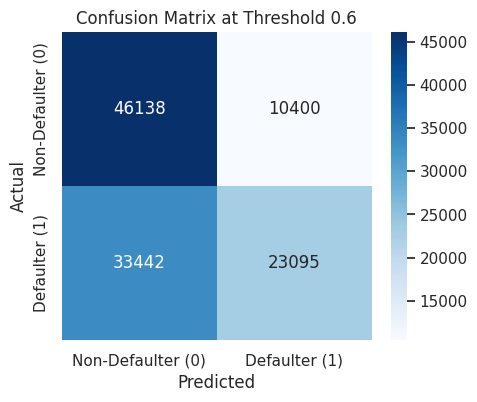

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Train Logistic Regression model on the outlier-treated and balanced dataset
lr_model_treated = LogisticRegression(max_iter=1000, random_state=42)
lr_model_treated.fit(X_train, y_train)

# Predict probabilities for the test set
y_probs = lr_model_treated.predict_proba(X_test)[:, 1]

# Evaluate predictions at a custom threshold of 0.6
def evaluate_at_threshold(probabilities, y_true, threshold):
    y_pred_custom = (probabilities >= threshold).astype(int)

    print(f"=== Classification Report at Threshold: {threshold} ===")
    print(classification_report(y_true, y_pred_custom))

    # Plot confusion matrix
    cm = confusion_matrix(y_true, y_pred_custom)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Non-Defaulter (0)', 'Defaulter (1)'],
                yticklabels=['Non-Defaulter (0)', 'Defaulter (1)'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title(f'Confusion Matrix at Threshold {threshold}')
    plt.show()

evaluate_at_threshold(y_probs, y_test, threshold=0.6)

=== Classification Report at Threshold: 0.6 ===
              precision    recall  f1-score   support

           0       0.74      0.98      0.84     56538
           1       0.96      0.66      0.79     56537

    accuracy                           0.82    113075
   macro avg       0.85      0.82      0.82    113075
weighted avg       0.85      0.82      0.82    113075



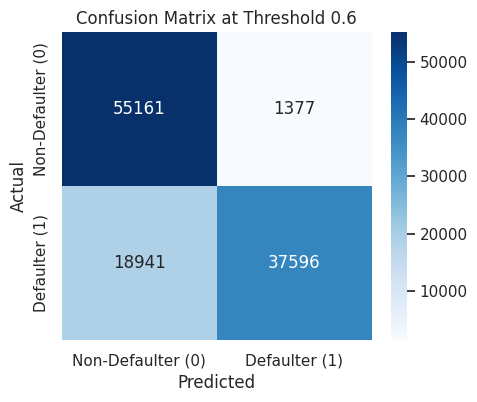

In [26]:
from sklearn.ensemble import RandomForestClassifier

# Train Random Forest classifier on the outlier-treated and balanced dataset
rf_model_treated = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
rf_model_treated.fit(X_train, y_train)

# Predict probabilities for the test set
y_probs_rf = rf_model_treated.predict_proba(X_test)[:, 1]

# Evaluate predictions at the custom threshold of 0.6
evaluate_at_threshold(y_probs_rf, y_test, threshold=0.6)

In [27]:
from sklearn.model_selection import GridSearchCV

# Define the hyperparameter grid to tune
param_grid = {
    'n_estimators': [100, 150],
    'max_depth': [12, 16],
    'min_samples_split': [2, 5]
}

# Initialize a base Random Forest classifier
rf_base = RandomForestClassifier(random_state=42, n_jobs=-1)

# Setup GridSearchCV with 3-fold cross-validation
grid_search = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

# Fit the grid search to training data
print("Starting grid search hyperparameter tuning...")
grid_search.fit(X_train, y_train)

print(f"Best Hyperparameters found: {grid_search.best_params_}")
best_rf_model = grid_search.best_estimator_

Starting grid search hyperparameter tuning...
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best Hyperparameters found: {'max_depth': 16, 'min_samples_split': 2, 'n_estimators': 150}


=== Classification Report at Threshold: 0.6 ===
              precision    recall  f1-score   support

           0       0.79      0.98      0.87     56538
           1       0.97      0.74      0.84     56537

    accuracy                           0.86    113075
   macro avg       0.88      0.86      0.86    113075
weighted avg       0.88      0.86      0.86    113075



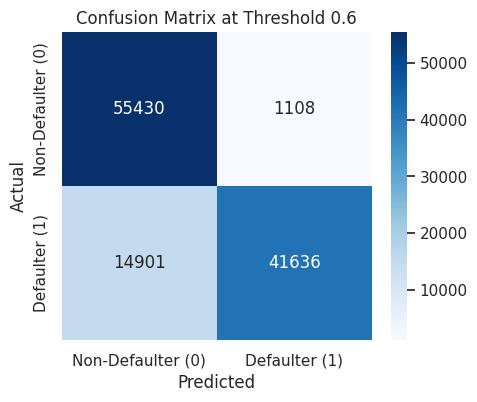

In [28]:
# Predict probabilities using the best tuned Random Forest model
y_probs_best_rf = best_rf_model.predict_proba(X_test)[:, 1]

# Evaluate the tuned model at the custom threshold of 0.6
evaluate_at_threshold(y_probs_best_rf, y_test, threshold=0.6)

=== Classification Report at Threshold: 0.6 ===
              precision    recall  f1-score   support

           0       0.91      1.00      0.95     56538
           1       1.00      0.90      0.94     56537

    accuracy                           0.95    113075
   macro avg       0.95      0.95      0.95    113075
weighted avg       0.95      0.95      0.95    113075



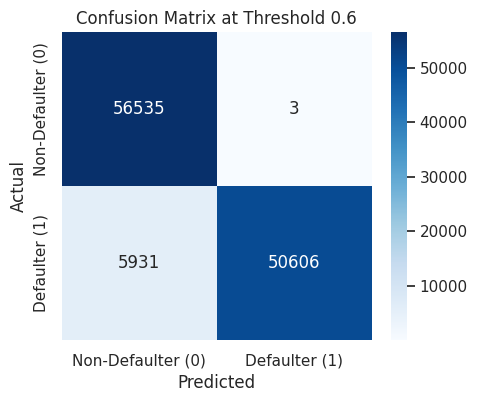

In [29]:
from xgboost import XGBClassifier

# Initialize and train the XGBoost Classifier
xgb_model = XGBClassifier(
    n_estimators=150,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1,
    eval_metric='logloss'
)

xgb_model.fit(X_train, y_train)

# Predict probabilities for the test set
y_probs_xgb = xgb_model.predict_proba(X_test)[:, 1]

# Evaluate predictions at the custom threshold of 0.6
evaluate_at_threshold(y_probs_xgb, y_test, threshold=0.6)

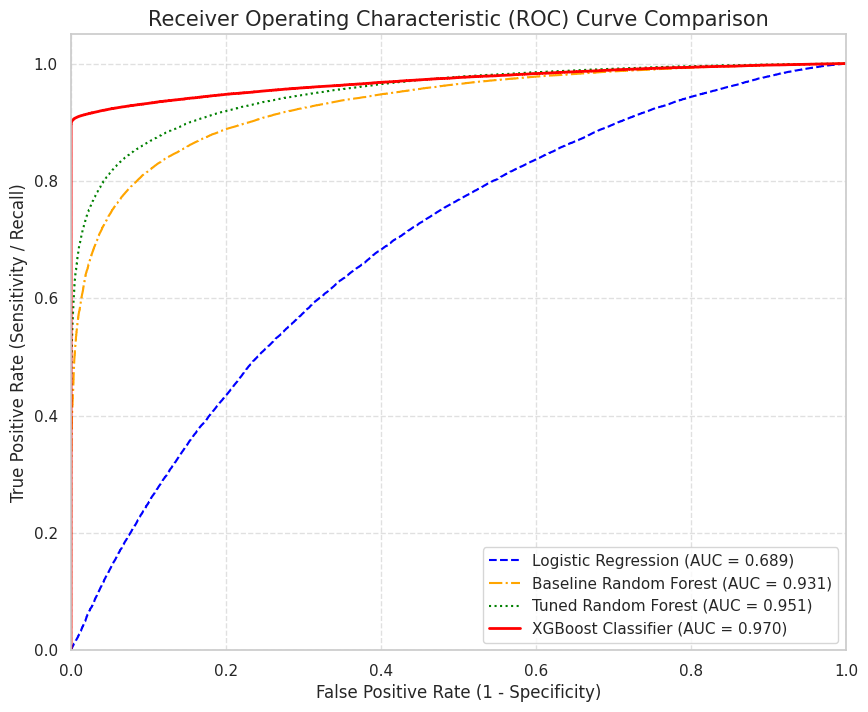

In [30]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Calculate AUC scores
auc_lr = roc_auc_score(y_test, y_probs)
auc_rf = roc_auc_score(y_test, y_probs_rf)
auc_best_rf = roc_auc_score(y_test, y_probs_best_rf)
auc_xgb = roc_auc_score(y_test, y_probs_xgb)

# Calculate ROC curves
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_probs)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_probs_rf)
fpr_best_rf, tpr_best_rf, _ = roc_curve(y_test, y_probs_best_rf)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_probs_xgb)

# Plot the curves
plt.figure(figsize=(10, 8))
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {auc_lr:.3f})', color='blue', linestyle='--')
plt.plot(fpr_rf, tpr_rf, label=f'Baseline Random Forest (AUC = {auc_rf:.3f})', color='orange', linestyle='-.')
plt.plot(fpr_best_rf, tpr_best_rf, label=f'Tuned Random Forest (AUC = {auc_best_rf:.3f})', color='green', linestyle=':')
plt.plot(fpr_xgb, tpr_xgb, label=f'XGBoost Classifier (AUC = {auc_xgb:.3f})', color='red', linewidth=2)

# Plot random guessing line


plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Curve Comparison', fontsize=15)
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### **6. Overfitting Diagnostics**
To check if our models are overfitting to the training set, we will compare their performance (Accuracy, F1-Score, and ROC-AUC) on both the **Training** and **Testing** sets.

In [32]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Helper function to get train & test performance
def get_performance_metrics(model, X_tr, y_tr, X_te, y_te, name):
    # Predictions & Probabilities
    y_tr_pred = model.predict(X_tr)
    y_te_pred = model.predict(X_te)

    # Handle models that output float probabilities directly vs sklearn API
    if hasattr(model, "predict_proba"):
        y_tr_prob = model.predict_proba(X_tr)[:, 1]
        y_te_prob = model.predict_proba(X_te)[:, 1]
    else:
        y_tr_prob = y_tr_pred
        y_te_prob = y_te_pred

    metrics = {
        'Model': name,
        'Train Accuracy': accuracy_score(y_tr, y_tr_pred),
        'Test Accuracy': accuracy_score(y_te, y_te_pred),
        'Train F1': f1_score(y_tr, y_tr_pred),
        'Test F1': f1_score(y_te, y_te_pred),
        'Train AUC': roc_auc_score(y_tr, y_tr_prob),
        'Test AUC': roc_auc_score(y_te, y_te_prob)
    }
    return metrics

# Compute metrics for our key models
results_list = []
results_list.append(get_performance_metrics(lr_model_treated, X_train, y_train, X_test, y_test, 'Logistic Regression'))
results_list.append(get_performance_metrics(best_rf_model, X_train, y_train, X_test, y_test, 'Tuned Random Forest'))
results_list.append(get_performance_metrics(xgb_model, X_train, y_train, X_test, y_test, 'XGBoost'))

# Create a summary DataFrame
results_df = pd.DataFrame(results_list)
display(results_df.round(4))

# Reshape data for visualization
plot_data = []
for _, row in results_df.iterrows():
    plot_data.append({'Model': row['Model'], 'Metric': 'Accuracy', 'Train': row['Train Accuracy'], 'Test': row['Test Accuracy']})
    plot_data.append({'Model': row['Model'], 'Metric': 'F1-Score', 'Train': row['Train F1'], 'Test': row['Test F1']})
    plot_data.append({'Model': row['Model'], 'Metric': 'ROC-AUC', 'Train': row['Train AUC'], 'Test': row['Test AUC']})

plot_df = pd.DataFrame(plot_data)
plot_df_melted = pd.melt(plot_df, id_vars=['Model', 'Metric'], value_vars=['Train', 'Test'], var_name='Dataset', value_name='Score')



,Model,Train Accuracy,Test Accuracy,Train F1,Test F1,Train AUC,Test AUC
0,Logistic Regression,0.6377,0.6413,0.6413,0.6446,0.6864,0.6892
1,Tuned Random Forest,0.8939,0.8848,0.8902,0.8803,0.9640,0.9506
2,XGBoost,0.9501,0.9501,0.9475,0.9475,0.9720,0.9702
